# Waze vs the incident register · checkpoint 4

Catch-up notebook: one way to get here, with its output. Done so far: queues against the register and the travel times.

Run all the cells (Runtime › Run all), then continue the exercise from the end of this notebook with your own code.

In [1]:
# The tools for today: pandas for tables, geopandas for maps and distances, matplotlib for plots.
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# Where the data files are: next to the notebook if there is a data folder,
# otherwise read straight from the course repository on GitHub (this is the case in Colab).
DATA = "https://raw.githubusercontent.com/daniel-verdugo/upm-data-integration/main/3.1-data-integration/session14/data/"
if os.path.isdir("data"):
    DATA = "data/"
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 150   # sharper plots
pd.set_option("display.max_columns", 30)

## 1 · The feed: what is one row?

One line of `waze_feed.jsonl` is one poll of the partner feed, every 5 minutes, exactly as Waze
returns it. Field meanings: the official *Waze Data Feed specifications*
(https://support.google.com/waze/partners/answer/13458165).

In [2]:
# Read the Waze feed. The file has one JSON object per line, and each line is one poll.
# shape tells me how many polls (rows) and fields (columns) I have.
polls = pd.read_json(DATA + "waze_feed.jsonl", lines=True)
polls.shape

(12096, 6)

In [3]:
# A first look: each poll has its time window and, inside, a list of alerts and a list of jams.
polls.head()

,endTimeMillis,startTimeMillis,startTime,endTime,alerts,jams
0,1769986835790,1769986775790,2026-02-01 22:59:35:000,2026-02-01 23:00:35:000,NaN,NaN
1,1769987131479,1769987071479,2026-02-01 23:04:31:000,2026-02-01 23:05:31:000,NaN,NaN
2,1769987435609,1769987375609,2026-02-01 23:09:35:000,2026-02-01 23:10:35:000,NaN,NaN
3,1769987730105,1769987670105,2026-02-01 23:14:30:000,2026-02-01 23:15:30:000,NaN,NaN
4,1769988038087,1769987978087,2026-02-01 23:19:38:000,2026-02-01 23:20:38:000,NaN,NaN


Each poll carries a list of alerts. `explode` gives one row per alert in a poll:

In [4]:
# I want one row per alert. explode splits each list of alerts into separate rows.
# Polls without alerts leave an empty row, so I drop those.
alert_rows = polls[["endTimeMillis", "alerts"]].explode("alerts")
alert_rows = alert_rows.dropna(subset=["alerts"])
alert_rows.shape

(7618, 2)

In [5]:
# Each alert is still a dictionary. json_normalize turns its fields into columns
# (location becomes location.x and location.y). I also keep the poll time, to know when it was seen.
alerts = pd.json_normalize(alert_rows["alerts"].tolist())
alerts["poll_ms"] = alert_rows["endTimeMillis"].values
alerts.head()

,country,reportRating,reportByMunicipalityUser,reliability,type,uuid,roadType,magvar,subtype,pubMillis,confidence,nThumbsUp,street,location.x,location.y,poll_ms
0,SP,3,false,8,HAZARD,024e0f17-8e37-48fe-97f3-bf85b5299431,3,73,HAZARD_ON_ROAD_CAR_STOPPED,1769989182613,0,0,AP-34,-4.902474,41.646961,1769989535119
1,SP,3,false,8,HAZARD,024e0f17-8e37-48fe-97f3-bf85b5299431,3,73,HAZARD_ON_ROAD_CAR_STOPPED,1769989182613,0,0,AP-34,-4.902474,41.646961,1769989838479
2,SP,3,false,8,HAZARD,024e0f17-8e37-48fe-97f3-bf85b5299431,3,73,HAZARD_ON_ROAD_CAR_STOPPED,1769989182613,0,0,AP-34,-4.902474,41.646961,1769990130332
3,SP,3,false,8,HAZARD,024e0f17-8e37-48fe-97f3-bf85b5299431,3,73,HAZARD_ON_ROAD_CAR_STOPPED,1769989182613,0,0,AP-34,-4.902474,41.646961,1769990435299
4,SP,3,false,8,HAZARD,024e0f17-8e37-48fe-97f3-bf85b5299431,3,73,HAZARD_ON_ROAD_CAR_STOPPED,1769989182613,0,0,AP-34,-4.902474,41.646961,1769990735345


In [6]:
# How many different alerts are there really? Fewer than rows: the same uuid repeats.
alerts["uuid"].nunique()

1129

One row is **one alert in one poll**. An alert stays in the feed while it is active, so the same
`uuid` appears in many polls, and its `reliability` and `confidence` change along the way.

In [7]:
# In how many polls does each alert appear? This confirms the grain: one alert in one poll.
alerts.groupby("uuid").size().describe()

count    1129.000000
mean        6.747564
std         4.421403
min         1.000000
25%         3.000000
50%         6.000000
75%        10.000000
max        24.000000
dtype: float64

## 2 · From polls to alerts (one row per `uuid`)

In [8]:
# Now one row per alert. I group the rows of each uuid and keep the first value of the fields
# that do not change, the first and last poll it was seen in, and the highest reliability
# and confidence it reached.
ev = alerts.sort_values("poll_ms").groupby("uuid").agg(
    type=("type", "first"),
    subtype=("subtype", "first"),
    street=("street", "first"),
    pubMillis=("pubMillis", "first"),
    first_poll=("poll_ms", "min"),
    last_poll=("poll_ms", "max"),
    reliability=("reliability", "max"),
    confidence=("confidence", "max"),
    x=("location.x", "first"),
    y=("location.y", "first"),
    magvar=("magvar", "first"),
)
len(ev)

1129

In [9]:
# What kinds of alerts are there? Many of them are probably not incidents the operator logs.
ev.groupby(["type", "subtype"]).size().sort_values(ascending=False)

type      subtype                       
HAZARD    HAZARD_ON_SHOULDER_CAR_STOPPED    430
          HAZARD_ON_ROAD_LANE_CLOSED        110
          HAZARD_ON_ROAD_CAR_STOPPED         94
          HAZARD_ON_ROAD_CONSTRUCTION        88
JAM       JAM_HEAVY_TRAFFIC                  71
HAZARD    HAZARD_ON_ROAD_OBJECT              67
ACCIDENT                                     54
JAM       JAM_STAND_STILL_TRAFFIC            53
                                             48
HAZARD    HAZARD_ON_ROAD                     32
          HAZARD_WEATHER_FOG                 28
          HAZARD_WEATHER                     18
          HAZARD_ON_ROAD_POT_HOLE            14
ACCIDENT  ACCIDENT_MAJOR                     10
HAZARD    HAZARD_ON_SHOULDER_ANIMALS          9
ACCIDENT  ACCIDENT_MINOR                      3
dtype: int64

## 3 · Time: epoch milliseconds in UTC

`pubMillis` is milliseconds since 1970 in UTC. The register is in local time (Madrid, UTC+1 in
February and March), without a zone.

In [10]:
# pubMillis is milliseconds since 1970, in UTC. I turn it into a date and tell pandas it is UTC.
pub_utc = pd.to_datetime(ev["pubMillis"], unit="ms", utc=True)
pub_utc.head()

uuid
00831f45-df44-4a29-bd5b-0d5eb76aaa52   2026-02-25 16:01:17.640000+00:00
00fb3c8f-2173-4ed4-94af-83da1a43f662   2026-02-28 16:40:07.441000+00:00
0108fce1-3f67-477a-94eb-2245f5ba64aa   2026-03-15 15:31:32.078000+00:00
0132eb42-8938-470a-9528-1794fee8603a   2026-02-02 08:57:48.313000+00:00
01776005-fe3d-425f-a865-00a6dc56801f   2026-02-05 22:47:34.272000+00:00
Name: pubMillis, dtype: datetime64[ns, UTC]

In [11]:
# Same instant, Madrid clock: in February it shows one hour more than UTC.
pub_madrid = pub_utc.dt.tz_convert("Europe/Madrid")
pub_madrid.head()

uuid
00831f45-df44-4a29-bd5b-0d5eb76aaa52   2026-02-25 17:01:17.640000+01:00
00fb3c8f-2173-4ed4-94af-83da1a43f662   2026-02-28 17:40:07.441000+01:00
0108fce1-3f67-477a-94eb-2245f5ba64aa   2026-03-15 16:31:32.078000+01:00
0132eb42-8938-470a-9528-1794fee8603a   2026-02-02 09:57:48.313000+01:00
01776005-fe3d-425f-a865-00a6dc56801f   2026-02-05 23:47:34.272000+01:00
Name: pubMillis, dtype: datetime64[ns, Europe/Madrid]

In [12]:
# The register uses local times with no zone, so I drop the zone to be able to compare them.
# I do the same for the first and last time each alert was seen.
# I also keep the UTC version, only to show later what happens if this step is forgotten.
ev["pub"] = pub_madrid.dt.tz_localize(None)
ev["pub_utc"] = pub_utc.dt.tz_localize(None)   # kept only to show the classic mistake in section 7
ev["first_seen"] = pd.to_datetime(ev["first_poll"], unit="ms", utc=True).dt.tz_convert("Europe/Madrid").dt.tz_localize(None)
ev["last_seen"] = pd.to_datetime(ev["last_poll"], unit="ms", utc=True).dt.tz_convert("Europe/Madrid").dt.tz_localize(None)
ev[["pub", "first_seen", "last_seen"]].head()

,pub,first_seen,last_seen
uuid,,,
00831f45-df44-4a29-bd5b-0d5eb76aaa52,2026-02-25 17:01:17.640,2026-02-25 17:05:31.010,2026-02-25 17:55:35.621
00fb3c8f-2173-4ed4-94af-83da1a43f662,2026-02-28 17:40:07.441,2026-02-28 17:50:33.018,2026-02-28 18:10:35.444
0108fce1-3f67-477a-94eb-2245f5ba64aa,2026-03-15 16:31:32.078,2026-03-15 16:45:34.683,2026-03-15 16:45:34.683
0132eb42-8938-470a-9528-1794fee8603a,2026-02-02 09:57:48.313,2026-02-02 10:05:36.849,2026-02-02 11:00:30.043
01776005-fe3d-425f-a865-00a6dc56801f,2026-02-05 23:47:34.272,2026-02-05 23:50:32.510,2026-02-06 00:10:33.960


In [13]:
# How long does an alert stay in the feed? Last seen minus first seen, in minutes.
ev["minutes_alive"] = (ev["last_seen"] - ev["first_seen"]).dt.total_seconds() / 60
ev["minutes_alive"].describe()

count    1129.000000
mean       28.737577
std        22.107458
min         0.000000
25%        10.075350
50%        24.931700
75%        44.904000
max       114.940417
Name: minutes_alive, dtype: float64

## 4 · Where is each alert? From lon/lat to road, PK and direction

`street` is not reliable: missing, written in several ways, and the feed polygon also covers the
old national road.

In [14]:
# Can the street name tell me which alerts are on the motorway? Let me see what it contains.
ev["street"].value_counts(dropna=False)

street
AP-34                842
N-334                123
None                  94
AP34                  56
Salida 42 · AP-34     14
Name: count, dtype: int64

In [15]:
# The motorway axis: a single line, with PK 42 at its first point.
road = gpd.read_file(DATA + "eje.geojson")
road

,road,pk_start,pk_end,geometry
0,AP-34,42.0,57.0,"LINESTRING (-5.05 41.62, -5.04882 41.62019, -5..."


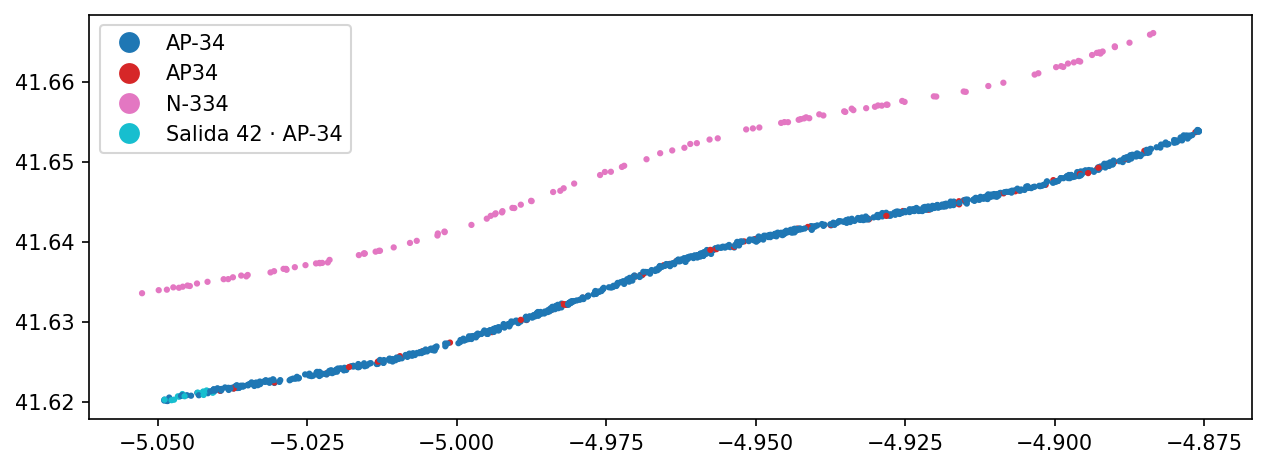

In [16]:
# I turn each alert into a point on the map (longitude, latitude: EPSG:4326) and colour it by
# street, to see where each street value really is.
points = gpd.GeoDataFrame(ev, geometry=gpd.points_from_xy(ev["x"], ev["y"]), crs=4326)
points.plot(column="street", legend=True, markersize=4, figsize=(10, 4))
plt.show()

Distances need metres, so both layers go to EPSG:25830 (ETRS89 / UTM 30N). Then each point is
projected on the road line: the distance along the line is the PK, the distance to the line says
whether the point is on the AP-34 at all.

In [17]:
# To measure in metres, I move both layers to EPSG:25830 (UTM zone 30, in metres).
# line is the axis itself, the geometry I measure against.
points = points.to_crs(25830)
road = road.to_crs(25830)
line = road.geometry.iloc[0]

In [18]:
# For each alert: how far it is from the axis (metres), and how far along the axis it falls.
# The distance along the line, in km, plus 42 is the PK.
points["dist_m"] = points.distance(line)
points["pk"] = 42 + points.geometry.apply(line.project) / 1000
points[["street", "dist_m", "pk"]].head()

,street,dist_m,pk
uuid,,,
00831f45-df44-4a29-bd5b-0d5eb76aaa52,N-334,1505.389992,43.888866
00fb3c8f-2173-4ed4-94af-83da1a43f662,None,1507.320257,53.387114
0108fce1-3f67-477a-94eb-2245f5ba64aa,AP-34,30.507159,43.334046
0132eb42-8938-470a-9528-1794fee8603a,AP-34,11.277251,49.725718
01776005-fe3d-425f-a865-00a6dc56801f,AP-34,13.408520,50.167797


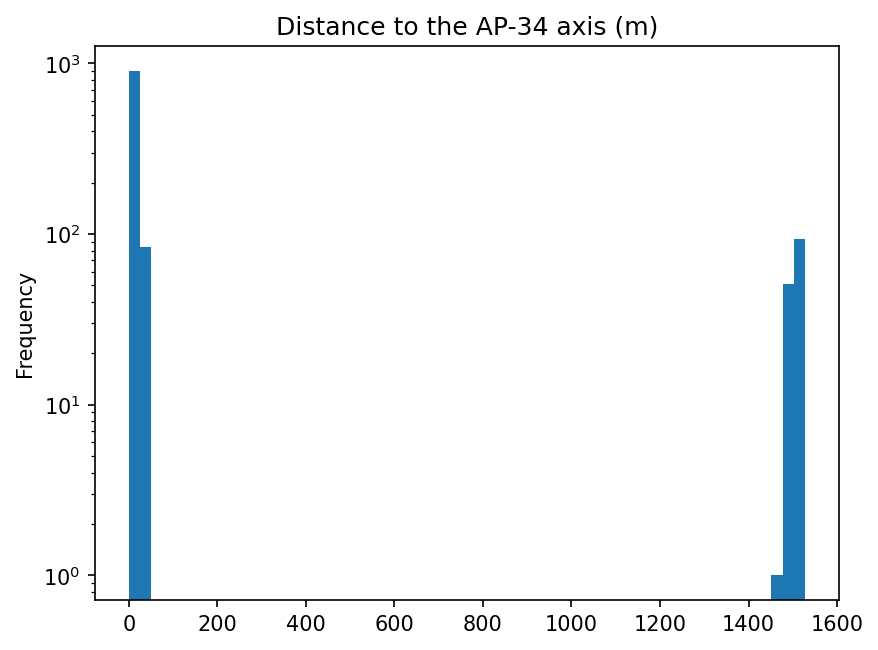

In [19]:
# Are there alerts far from the motorway? A histogram of the distances shows the groups.
# Log scale, so that a small group is still visible.
points["dist_m"].plot.hist(bins=60, log=True, title="Distance to the AP-34 axis (m)")
plt.show()

In [20]:
# Keep the alerts within 100 m of the axis: those are on the motorway.
# Any cut between the two groups of the histogram gives the same result.
on_road = points[points["dist_m"] < 100].copy()
len(on_road)

984

In [21]:
# Check: which street names are left? Only spellings of the motorway, and missing names.
on_road["street"].value_counts(dropna=False)

street
AP-34                842
None                  72
AP34                  56
Salida 42 · AP-34     14
Name: count, dtype: int64

Direction: both carriageways are a few metres apart, so position cannot tell them apart.
`magvar` is the driver's heading (0 = north). The stretch runs roughly east-north-east.

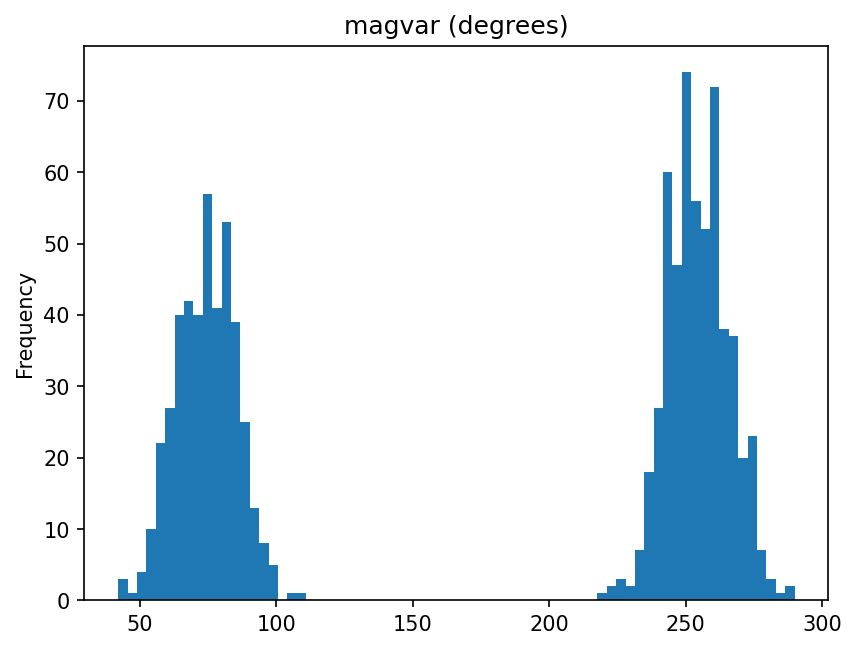

In [22]:
# Which carriageway? Position cannot tell: they are a few metres apart. magvar is the driver's
# heading when reporting; if the histogram shows two peaks, they are the two directions.
on_road["magvar"].plot.hist(bins=72, title="magvar (degrees)")
plt.show()

In [23]:
# The road heads roughly east-north-east (about 75 degrees). Headings below 180 go towards
# higher PKs (Creciente), the rest the other way. I set everything to Decreciente, then overwrite.
on_road["sentido"] = "Decreciente"
on_road.loc[on_road["magvar"] < 180, "sentido"] = "Creciente"
on_road["sentido"].value_counts()

sentido
Decreciente    552
Creciente      432
Name: count, dtype: int64

## 5 · The register: the ground truth

In [24]:
# The operator's incident register: one row per incident, already closed. This is the reference.
reg = pd.read_csv(DATA + "registro_incidencias.csv")
reg.head()

,id_incidencia,inicio,fin,tipo,pk,sentido,carriles_afectados,retencion_km,vehiculos_implicados,heridos,causa
0,INC-0101,02/02/2026 00:46,02/02/2026 01:20,TURISMO AVERIADO,"54,8",Creciente,1,NaN,NaN,NaN,averia
1,INC-0102,04/02/2026 16:47,04/02/2026 17:22,CAMION AVERIADO,"55,3",Decreciente,1,NaN,NaN,NaN,REVENTON
2,INC-0103,05/02/2026 13:37,05/02/2026 15:19,ACCIDENTE,"43,2",Decreciente,1,NaN,3.0,1.0,Alcance
3,INC-0104,06/02/2026 17:29,06/02/2026 19:22,Retención,"42,4",Decreciente,0,"2,6",NaN,NaN,Tráfico denso
4,INC-0105,06/02/2026 21:27,06/02/2026 22:35,Accidente,"50,7",Creciente,2,NaN,1.0,0.0,ALCANCE


In [25]:
# Make the register usable: dates are day-first text in local time, and the PK has a decimal
# comma. Then I look at the incident types as they are written.
reg["inicio"] = pd.to_datetime(reg["inicio"], format="%d/%m/%Y %H:%M")
reg["fin"] = pd.to_datetime(reg["fin"], format="%d/%m/%Y %H:%M")
reg["pk"] = reg["pk"].str.replace(",", ".").astype(float)
reg["tipo"].value_counts()

tipo
TURISMO AVERIADO     9
ACCIDENTE            9
VEHICULO AVERIADO    8
RETENCION            7
RETENCIONES          6
Objeto en calzada    5
Accidente            5
CAMION AVERIADO      3
Retención            3
OBJETO EN CALZADA    3
Vehículo averiado    3
Camión averiado      3
Name: count, dtype: int64

In [26]:
# The same type is written in several ways. Upper case, and accents removed
# (NFKD splits É into E + accent; the ascii step drops the accent).
reg["tipo_norm"] = reg["tipo"].str.upper()
reg["tipo_norm"] = reg["tipo_norm"].str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("ascii")
reg["tipo_norm"].value_counts()

tipo_norm
ACCIDENTE            14
VEHICULO AVERIADO    11
RETENCION            10
TURISMO AVERIADO      9
OBJETO EN CALZADA     8
CAMION AVERIADO       6
RETENCIONES           6
Name: count, dtype: int64

In [27]:
# Map each normalised type to a common category. A NaN left here would be a type I forgot.
TIPO = {
    "ACCIDENTE": "accident",
    "VEHICULO AVERIADO": "breakdown",
    "CAMION AVERIADO": "breakdown",
    "TURISMO AVERIADO": "breakdown",
    "OBJETO EN CALZADA": "object",
    "RETENCION": "queue",
    "RETENCIONES": "queue",
}
reg["category"] = reg["tipo_norm"].map(TIPO)
reg["category"].value_counts(dropna=False)

category
breakdown    26
queue        16
accident     14
object        8
Name: count, dtype: int64

## 6 · Scope: which Waze alerts can be compared with the register?

The register logs incidents the operator acted on. Most Waze alerts are things the operator does
not log: cars stopped on the hard shoulder for a few minutes, planned works, fog. A mapping table
keeps the comparable part.

In [28]:
# Waze describes an alert with two fields. I join them into one text, which is easier to map.
on_road["type_subtype"] = on_road["type"] + " / " + on_road["subtype"]
on_road["type_subtype"].value_counts()

type_subtype
HAZARD / HAZARD_ON_SHOULDER_CAR_STOPPED    383
HAZARD / HAZARD_ON_ROAD_LANE_CLOSED        110
HAZARD / HAZARD_ON_ROAD_CONSTRUCTION        88
HAZARD / HAZARD_ON_ROAD_CAR_STOPPED         62
JAM / JAM_STAND_STILL_TRAFFIC               53
JAM / JAM_HEAVY_TRAFFIC                     50
JAM /                                       48
HAZARD / HAZARD_ON_ROAD_OBJECT              45
HAZARD / HAZARD_ON_ROAD                     32
ACCIDENT /                                  31
HAZARD / HAZARD_WEATHER_FOG                 28
HAZARD / HAZARD_WEATHER                     18
HAZARD / HAZARD_ON_ROAD_POT_HOLE            14
ACCIDENT / ACCIDENT_MAJOR                   10
HAZARD / HAZARD_ON_SHOULDER_ANIMALS          9
ACCIDENT / ACCIDENT_MINOR                    3
Name: count, dtype: int64

In [29]:
# Only some Waze types are comparable with the register. I map those to the same categories
# as the register and keep only the alerts that got one.
WAZE = {
    "ACCIDENT / ": "accident",
    "ACCIDENT / ACCIDENT_MAJOR": "accident",
    "ACCIDENT / ACCIDENT_MINOR": "accident",
    "HAZARD / HAZARD_ON_ROAD_CAR_STOPPED": "breakdown",
    "HAZARD / HAZARD_ON_ROAD_OBJECT": "object",
}
on_road["category"] = on_road["type_subtype"].map(WAZE)
waze = on_road[on_road["category"].notna()]
len(waze)

151

In [30]:
# How reliable are the comparable alerts? Reliability goes from 5 (a new report) to 10.
waze["reliability"].value_counts().sort_index()

reliability
5     43
6     43
7     17
8     14
9     10
10    24
Name: count, dtype: int64

## 7 · Matching without a key

No shared id. A Waze alert and a register incident are taken as the same event when they are in
the same direction, at most 1 km apart, and the alert is published between 30 min before the
register's start and its end. Category is not required to match: drivers and operators label
differently.

In [31]:
# For this comparison I keep the register incidents that are not queues (queues come later).
inc = reg[reg["category"] != "queue"]
len(inc)

48

In [32]:
# There is no common key. I pair every alert with every incident in the same direction, and
# filter afterwards. Suffixes: _w for the Waze columns, _r for the register columns.
pairs = waze.reset_index().merge(inc, on="sentido", suffixes=("_w", "_r"))
len(pairs)

3674

In [33]:
# Keep the pairs that are close: at most 1 km apart, and the alert published between
# 30 min before the register's start and its end.
close_in_pk = (pairs["pk_w"] - pairs["pk_r"]).abs() <= 1
in_window = (pairs["pub"] >= pairs["inicio"] - pd.Timedelta(minutes=30)) & (pairs["pub"] <= pairs["fin"])
matches = pairs[close_in_pk & in_window]
len(matches)

47

With every comparable alert (reliability 5 or more):

In [34]:
# Two numbers. Detected: share of register incidents with at least one matching alert.
# Real: share of Waze alerts that match some incident.
detected_5 = inc["id_incidencia"].isin(matches["id_incidencia"]).mean()
real_5 = waze.index.isin(matches["uuid"]).mean()
detected_5, real_5

(np.float64(0.7083333333333334), np.float64(0.31125827814569534))

Only alerts with reliability 6 or more:

In [35]:
# The same two numbers, keeping only the alerts with reliability 6 or more.
waze_6 = waze[waze["reliability"] >= 6]
matches_6 = matches[matches["reliability"] >= 6]
detected_6 = inc["id_incidencia"].isin(matches_6["id_incidencia"]).mean()
real_6 = waze_6.index.isin(matches_6["uuid"]).mean()
detected_6, real_6

(np.float64(0.6666666666666666), np.float64(0.4166666666666667))

Only alerts with reliability 7 or more:

In [36]:
# The same two numbers, keeping only the alerts with reliability 7 or more.
waze_7 = waze[waze["reliability"] >= 7]
matches_7 = matches[matches["reliability"] >= 7]
detected_7 = inc["id_incidencia"].isin(matches_7["id_incidencia"]).mean()
real_7 = waze_7.index.isin(matches_7["uuid"]).mean()
detected_7, real_7

(np.float64(0.6458333333333334), np.float64(0.6615384615384615))

Only alerts with reliability 8 or more:

In [37]:
# The same two numbers, keeping only the alerts with reliability 8 or more.
waze_8 = waze[waze["reliability"] >= 8]
matches_8 = matches[matches["reliability"] >= 8]
detected_8 = inc["id_incidencia"].isin(matches_8["id_incidencia"]).mean()
real_8 = waze_8.index.isin(matches_8["uuid"]).mean()
detected_8, real_8

(np.float64(0.5625), np.float64(0.6666666666666666))

Only alerts with reliability 9 or more:

In [38]:
# And again with reliability 9 or more.
waze_9 = waze[waze["reliability"] >= 9]
matches_9 = matches[matches["reliability"] >= 9]
detected_9 = inc["id_incidencia"].isin(matches_9["id_incidencia"]).mean()
real_9 = waze_9.index.isin(matches_9["uuid"]).mean()
detected_9, real_9

(np.float64(0.4583333333333333), np.float64(0.7058823529411765))

In [39]:
# The five results side by side, in a small table.
sensitivity = pd.DataFrame({
    "reliability at least": [5, 6, 7, 8, 9],
    "register incidents detected": [detected_5, detected_6, detected_7, detected_8, detected_9],
    "Waze alerts that are real": [real_5, real_6, real_7, real_8, real_9],
})
sensitivity

,reliability at least,register incidents detected,Waze alerts that are real
0,5,0.708333,0.311258
1,6,0.666667,0.416667
2,7,0.645833,0.661538
3,8,0.562500,0.666667
4,9,0.458333,0.705882


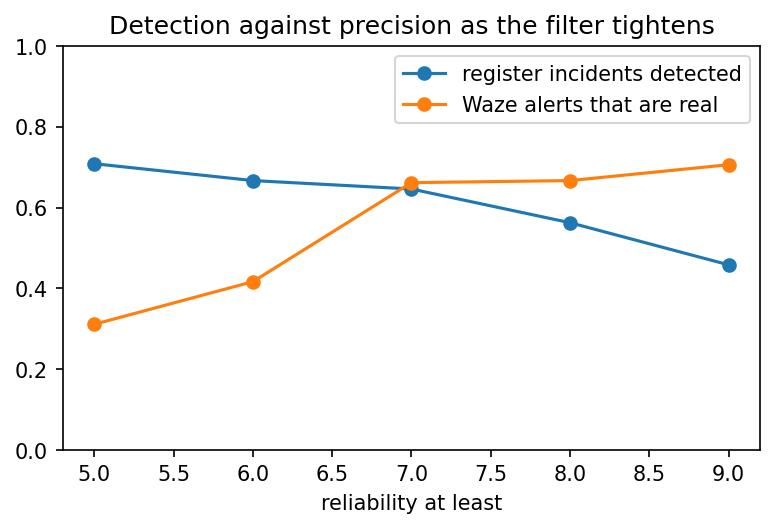

In [40]:
# As the filter gets stricter, more of the alerts are real, but fewer incidents are detected.
sensitivity.plot(x="reliability at least", marker="o", ylim=(0, 1), figsize=(6, 3.5))
plt.title("Detection against precision as the filter tightens")
plt.show()

How early does Waze report? First Waze alert minus the register's start, reliability 7 or more:

In [41]:
# How early is Waze? For each detected incident, its first matching alert minus the register's
# start, in minutes. Negative means Waze was first.
first_alert = matches_7.groupby("id_incidencia")["pub"].min()
register_start = inc.set_index("id_incidencia")["inicio"]
lead_min = (first_alert - register_start).dropna().dt.total_seconds() / 60
lead_min.describe()

count    31.000000
mean     -2.726920
std       5.741246
min     -19.651467
25%      -5.524200
50%      -2.823533
75%      -0.642075
max       9.696767
dtype: float64

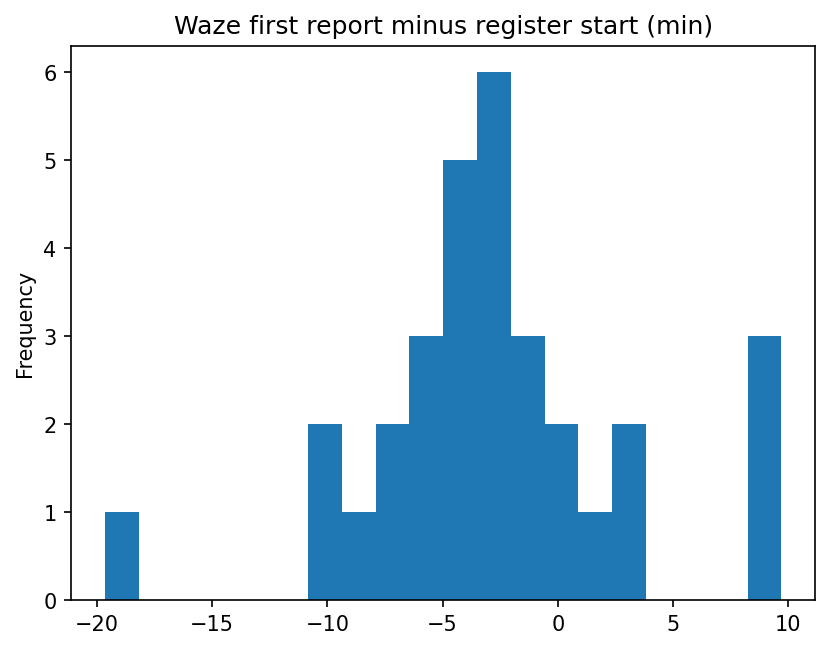

In [42]:
# The distribution of that difference.
lead_min.plot.hist(bins=20, title="Waze first report minus register start (min)")
plt.show()

What is missed, and why (night, breakdowns on the shoulder, reports filed from the other carriageway):

In [43]:
# Which incidents did Waze miss? Looking at them one by one helps to explain why.
missed = inc[~inc["id_incidencia"].isin(matches_7["id_incidencia"])]
missed[["id_incidencia", "inicio", "tipo", "pk", "sentido", "carriles_afectados"]]

,id_incidencia,inicio,tipo,pk,sentido,carriles_afectados
11,INC-0112,2026-02-10 15:31:00,TURISMO AVERIADO,54.8,Decreciente,0
14,INC-0115,2026-02-11 18:34:00,VEHICULO AVERIADO,49.7,Decreciente,0
15,INC-0116,2026-02-12 18:52:00,ACCIDENTE,48.0,Decreciente,0
18,INC-0119,2026-02-14 07:20:00,VEHICULO AVERIADO,54.0,Creciente,0
30,INC-0131,2026-02-22 11:34:00,TURISMO AVERIADO,45.8,Decreciente,1
33,INC-0134,2026-02-25 06:14:00,Vehículo averiado,43.4,Creciente,2
34,INC-0135,2026-02-25 18:46:00,ACCIDENTE,44.9,Creciente,0
35,INC-0136,2026-02-27 01:50:00,Camión averiado,51.9,Creciente,1
38,INC-0139,2026-02-28 07:51:00,VEHICULO AVERIADO,50.4,Creciente,1
40,INC-0141,2026-03-01 07:00:00,Camión averiado,42.6,Creciente,1


The classic mistake: comparing UTC times with the register's local times.

In [44]:
# What if I had compared UTC times with the register's local times?
# The same matching, with the UTC column I kept in section 3.
in_window_utc = (pairs["pub_utc"] >= pairs["inicio"] - pd.Timedelta(minutes=30)) & (pairs["pub_utc"] <= pairs["fin"])
matches_utc = pairs[close_in_pk & in_window_utc & (pairs["reliability"] >= 7)]
inc["id_incidencia"].isin(matches_utc["id_incidencia"]).mean()

np.float64(0.0)

## 8 · Queues: Waze jams against the register and the measured travel times

Jams are computed by Waze, not reported by drivers. Direction comes from the geometry: `line`
runs from the tail to the head of the queue.

In [45]:
# The same as with the alerts: one row per jam in each poll, then its fields as columns.
jam_rows = polls[["endTimeMillis", "jams"]].explode("jams")
jam_rows = jam_rows.dropna(subset=["jams"])
jams = pd.json_normalize(jam_rows["jams"].tolist())
jams["poll_ms"] = jam_rows["endTimeMillis"].values
jams[["uuid", "level", "length", "delay", "speedKMH"]].head()

,uuid,level,length,delay,speedKMH
0,1766607882,3,266,27,19.35
1,1766607882,3,561,77,20.82
2,1766607882,3,587,60,17.43
3,1766607882,3,391,39,19.03
4,1041611788,2,278,19,28.51


In [46]:
# Poll time to Madrid local time. For the direction I compare the first and last points of
# the jam's line: it runs from tail to head, so if x grows the traffic goes towards higher PKs.
jams["t"] = pd.to_datetime(jams["poll_ms"], unit="ms", utc=True).dt.tz_convert("Europe/Madrid").dt.tz_localize(None)
jams["x_tail"] = jams["line"].str[0].str["x"]
jams["x_head"] = jams["line"].str[-1].str["x"]
jams["sentido"] = "Decreciente"
jams.loc[jams["x_head"] > jams["x_tail"], "sentido"] = "Creciente"
jams["sentido"].value_counts()

sentido
Decreciente    312
Creciente      297
Name: count, dtype: int64

Register queues with at least one Waze jam in the same direction, from 30 min before their start to their end:

In [47]:
# Does every queue in the register have a Waze jam? I pair them by direction and keep the jams
# seen between 30 min before the queue's start and its end.
queues = reg[reg["category"] == "queue"]
queue_pairs = queues.merge(jams, on="sentido")
in_window = (queue_pairs["t"] >= queue_pairs["inicio"] - pd.Timedelta(minutes=30)) & (queue_pairs["t"] <= queue_pairs["fin"])
queues["id_incidencia"].isin(queue_pairs[in_window]["id_incidencia"]).mean()

np.float64(1.0)

Measured travel times: the excess over free flow, against the Waze delay, both per 15 min and direction.

In [48]:
# Travel times measured at the toll: mean time per 15 min and direction.
tt = pd.read_csv(DATA + "tiempos_recorrido.csv", parse_dates=["intervalo_inicio"])
tt.head()

,intervalo_inicio,sentido,n_trayectos,tiempo_medio_s
0,2026-02-02 00:00:00,Creciente,12,442.0
1,2026-02-02 00:00:00,Decreciente,6,453.0
2,2026-02-02 00:15:00,Creciente,3,NaN
3,2026-02-02 00:15:00,Decreciente,10,453.0
4,2026-02-02 00:30:00,Creciente,7,466.0


In [49]:
# Free flow: the usual time, taken as the median per direction.
# Excess: how much longer than usual each interval took.
tt["free_flow_s"] = tt.groupby("sentido")["tiempo_medio_s"].transform("median")
tt["excess_s"] = tt["tiempo_medio_s"] - tt["free_flow_s"]

In [50]:
# Bring the Waze jams to the same grain: mean delay per 15 min and direction.
# Then rename the time column so that it matches the travel-time table.
waze_delay = jams.set_index("t").groupby("sentido")["delay"].resample("15min").mean()
waze_delay = waze_delay.rename("waze_delay_s").reset_index()
waze_delay = waze_delay.rename(columns={"t": "intervalo_inicio"})
waze_delay.head()

,sentido,intervalo_inicio,waze_delay_s
0,Creciente,2026-02-04 17:00:00,23.333333
1,Creciente,2026-02-04 17:15:00,NaN
2,Creciente,2026-02-04 17:30:00,NaN
3,Creciente,2026-02-04 17:45:00,NaN
4,Creciente,2026-02-04 18:00:00,NaN


In [51]:
# Both side by side. Intervals with no jam get a Waze delay of 0.
# validate="1:1" checks that each interval appears once on each side.
q = tt.merge(waze_delay, on=["intervalo_inicio", "sentido"], how="left", validate="1:1")
q["waze_delay_s"] = q["waze_delay_s"].fillna(0)
q[["excess_s", "waze_delay_s"]].corr()

,excess_s,waze_delay_s
excess_s,1.000000,0.883197
waze_delay_s,0.883197,1.000000


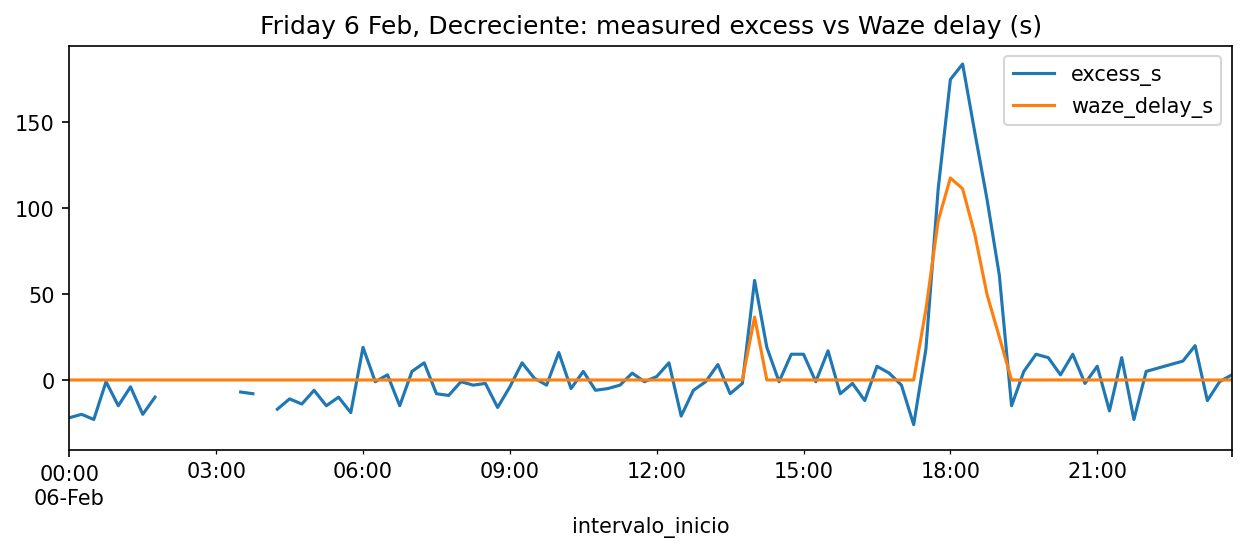

In [52]:
# One Friday, one direction: do the two series rise and fall together?
friday = q[(q["intervalo_inicio"].dt.date == pd.Timestamp("2026-02-06").date()) & (q["sentido"] == "Decreciente")]
friday.plot(x="intervalo_inicio", y=["excess_s", "waze_delay_s"], figsize=(10, 3.5),
            title="Friday 6 Feb, Decreciente: measured excess vs Waze delay (s)")
plt.show()

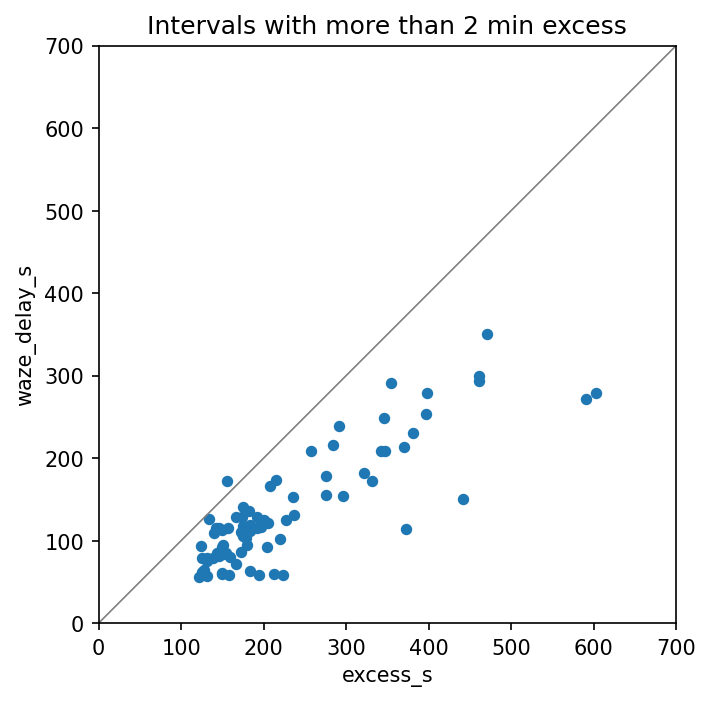

In [53]:
# Only the intervals with real congestion (more than 2 min extra). Points on the grey line would
# mean Waze matches the measurement; points below it mean Waze underestimates the delay.
# Both axes in seconds, with the same scale.
big = q[q["excess_s"] > 120]   # 2 minutes
ax = big.plot.scatter(x="excess_s", y="waze_delay_s", figsize=(5, 5), title="Intervals with more than 2 min excess")
ax.axline((0, 0), slope=1, color="grey", lw=0.8)
ax.set_xlim(0, 700)      # the same range on both axes...
ax.set_ylim(0, 700)
ax.set_aspect("equal")   # ...and the same scale, so distance to the grey line reads honestly
plt.show()

In [54]:
# A typical ratio: which fraction of the measured delay does Waze report?
(big["waze_delay_s"] / big["excess_s"]).median()

np.float64(0.6043735022252653)

**End of checkpoint 4.** From here on, the work is yours.